# CAPSTONE PROJECT
## Irregular Migration Across the Western Balkan Route, impact on Montenegro and prediction of the number of illegals by month in 2027

### Notebook 02.1. — Modeling and Recursive Forecasting for Montenegro Only

**Research question:** How can historical IOM DTM data be used to estimate recorded arrivals in Montenegro on the Western Balkan Route for the next 3, 6 and 12 months?

**Target:** monthly `Arrivals` from `Other_Countries_Areas_Monthly`, filtered to `Route == 'WBR'` and `ISO3 - Country of arrival == 'MNE'`.

These are recorded arrivals/events as defined by the source, not necessarily unique individuals. Forecasts are statistical estimates based on historical patterns, not certainties.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load the source sheet

In [2]:
file_path = '/content/DTM Europe_Q1_2026_Dataset.xlsx'

im1_2 = pd.read_excel(
    file_path,
    sheet_name='Other_Countries_Areas_Monthly'
)

im1_2['Date'] = pd.to_datetime(im1_2['Date'], errors='coerce')
im1_2['Arrivals'] = pd.to_numeric(im1_2['Arrivals'], errors='coerce')

print('Dataset shape:', im1_2.shape)
print('Route labels:')
print(im1_2['Route'].value_counts(dropna=False))
print('Montenegro records:', (im1_2['ISO3 - Country of arrival'] == 'MNE').sum())

Dataset shape: (1066, 7)
Route labels:
Route
WBR         724
EU Other    342
Name: count, dtype: int64
Montenegro records: 123


## 3. Filter Montenegro on the Western Balkan Route

The route code used in the EDA notebook is `WBR`. Inspect the printed route labels above. If the source displays a different exact label, change `ROUTE_CODE` to that exact value.

In [3]:
ROUTE_CODE = 'WBR'
MONTENEGRO_CODE = 'MNE'

df_mne = im1_2.dropna(subset=['Date', 'Arrivals']).copy()
df_mne = df_mne[
    (df_mne['Route'] == ROUTE_CODE) &
    (df_mne['ISO3 - Country of arrival'] == MONTENEGRO_CODE)
].copy()

print('Filtered rows for Montenegro on WBR:', len(df_mne))
print('Date range:', df_mne['Date'].min(), 'to', df_mne['Date'].max())

if df_mne.empty:
    raise ValueError('No records found. Check the exact route label and MNE country code.')

df_mne['Month'] = df_mne['Date'].dt.to_period('M').dt.to_timestamp()
mne_monthly = (
    df_mne.groupby('Month')['Arrivals']
    .sum()
    .sort_index()
)

display(mne_monthly.head())
display(mne_monthly.tail())
print('Monthly observations:', len(mne_monthly))
print('Total recorded arrivals in this filtered series:', mne_monthly.sum())

Filtered rows for Montenegro on WBR: 123
Date range: 2016-01-31 00:00:00 to 2026-03-31 00:00:00


,Arrivals
Month,
2016-01-01,81
2016-02-01,15
2016-03-01,3
2016-04-01,9
2016-05-01,2


,Arrivals
Month,
2025-11-01,364
2025-12-01,257
2026-01-01,203
2026-02-01,405
2026-03-01,453


Monthly observations: 123
Total recorded arrivals in this filtered series: 40897


## 4. Visualize Montenegro monthly arrivals

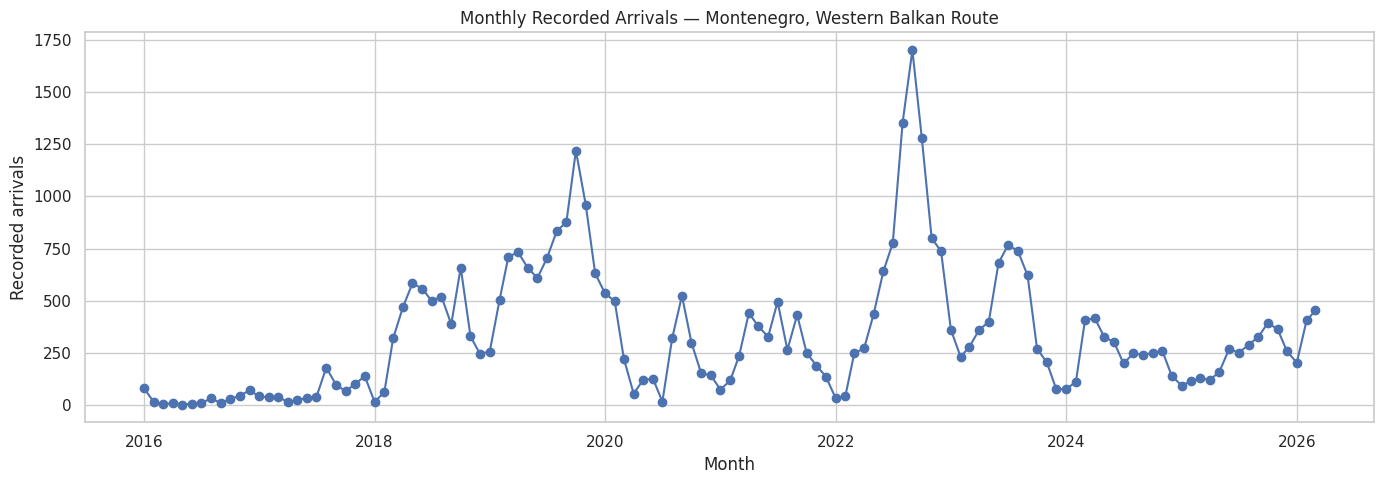

In [4]:
plt.figure(figsize=(14, 5))
plt.plot(mne_monthly.index, mne_monthly.values, marker='o')
plt.title('Monthly Recorded Arrivals — Montenegro, Western Balkan Route')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.tight_layout()
plt.show()

## 5. Check monthly continuity and data sufficiency

By processing the data, I tried to avoid automatic replacement of missing months with zero. First, I determined whether the missing month means that zero arrivals were recorded, or that the data from the source is missing, that is, not available. This approach requires a continuous monthly series and at least 36 observations.

In [5]:
expected_months = pd.date_range(
    start=mne_monthly.index.min(),
    end=mne_monthly.index.max(),
    freq='MS'
)
missing_months = expected_months.difference(mne_monthly.index)

print('Expected months:', len(expected_months))
print('Observed months:', len(mne_monthly))
print('Missing months:', len(missing_months))
print(missing_months)

if len(missing_months) > 0:
    raise ValueError(
        'There are missing months. Investigate the source first. '
        'Only add missing months as zero if the source confirms zero arrivals.'
    )

if len(mne_monthly) < 36:
    raise ValueError(
        f'Only {len(mne_monthly)} monthly observations are available. '
        'This setup needs at least 36 continuous months for the selected lags and evaluation.'
    )

target = mne_monthly.astype(float).copy()
TARGET_NAME = 'Montenegro — Western Balkan Route'
print('Modeling period:', target.index.min(), 'to', target.index.max())

Expected months: 123
Observed months: 123
Missing months: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')
Modeling period: 2016-01-01 00:00:00 to 2026-03-01 00:00:00


## 6. Feature Engineering

In [15]:
def make_features(series):
    data = pd.DataFrame({'Arrivals': series.copy()})
    data.index.name = 'Month'
    data['Time_Index'] = np.arange(len(data))
    data['Month_Number'] = data.index.month
    data['Month_Sin'] = np.sin(2 * np.pi * data['Month_Number'] / 12)
    data['Month_Cos'] = np.cos(2 * np.pi * data['Month_Number'] / 12)
    data['Lag_1'] = data['Arrivals'].shift(1)
    data['Lag_3'] = data['Arrivals'].shift(3)
    data['Lag_6'] = data['Arrivals'].shift(6)
    data['Lag_12'] = data['Arrivals'].shift(12)
    data['Rolling_Mean_3'] = data['Arrivals'].shift(1).rolling(3).mean()
    data['Rolling_Mean_6'] = data['Arrivals'].shift(1).rolling(6).mean()
    data = data.round(2)
    return data.dropna()

FEATURES = [
    'Time_Index', 'Month_Sin', 'Month_Cos',
    'Lag_1', 'Lag_3', 'Lag_6', 'Lag_12',
    'Rolling_Mean_3', 'Rolling_Mean_6'
]
feature_df = make_features(target)

X = feature_df[FEATURES]
y = feature_df['Arrivals']
display(feature_df.head())
print('Rows after feature engineering:', len(feature_df))

,Arrivals,Time_Index,Month_Number,Month_Sin,Month_Cos,Lag_1,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Mean_6
Month,,,,,,,,,,,
2017-01-01,41.0,12,1,0.50,0.87,70.0,28.0,9.0,81.0,47.67,32.00
2017-02-01,36.0,13,2,0.87,0.50,41.0,45.0,31.0,15.0,52.00,37.33
2017-03-01,39.0,14,3,1.00,0.00,36.0,70.0,9.0,3.0,49.00,38.17
2017-04-01,14.0,15,4,0.87,-0.50,39.0,41.0,28.0,9.0,38.67,43.17
2017-05-01,23.0,16,5,0.50,-0.87,14.0,36.0,45.0,2.0,29.67,40.83


Rows after feature engineering: 111


## 7. Chronological Train/Test split

The last 12 months are reserved for testing. Data is not shuffled because future observations must not be used to predict the past.

In [7]:
TEST_MONTHS = 12
if len(feature_df) <= TEST_MONTHS + 12:
    raise ValueError('Not enough feature rows for a 12-month test set and useful training period.')

X_train, X_test = X.iloc[:-TEST_MONTHS], X.iloc[-TEST_MONTHS:]
y_train, y_test = y.iloc[:-TEST_MONTHS], y.iloc[-TEST_MONTHS:]

print('Training:', X_train.index.min(), 'to', X_train.index.max())
print('Testing:', X_test.index.min(), 'to', X_test.index.max())
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Training: 2017-01-01 00:00:00 to 2025-03-01 00:00:00
Testing: 2025-04-01 00:00:00 to 2026-03-01 00:00:00
Training rows: 99 | Test rows: 12


## 8. Train candidate models

In [8]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10.0))
    ]),
    'Random Forest': RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_split=5,
        min_samples_leaf=2, random_state=42
    )
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'trained')

Linear Regression trained
Ridge Regression trained
Random Forest trained


## 9. Evaluate models and compare with a seasonal baseline

MAE and RMSE are measured in recorded arrivals; lower values are better. R² is supplementary and may be negative. The seasonal-naive baseline predicts each test month using the observed value from the same month one year earlier.

In [17]:
def calculate_metrics(actual, predicted):
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted)
    }

predictions = {}
metric_rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    metric_rows.append({'Model': name, **calculate_metrics(y_test, pred)})

seasonal_naive = target.reindex(y_test.index - pd.DateOffset(years=1))
seasonal_naive.index = y_test.index
if seasonal_naive.notna().all():
    predictions['Seasonal Naive'] = seasonal_naive.values
    metric_rows.append({
        'Model': 'Seasonal Naive',
        **calculate_metrics(y_test, seasonal_naive)
    })

results = pd.DataFrame(metric_rows).sort_values('MAE').round(2)
display(results)

,Model,MAE,RMSE,R2
0,Linear Regression,56.77,81.53,0.30
2,Random Forest,64.66,96.55,0.02
1,Ridge Regression,71.46,88.96,0.16
3,Seasonal Naive,146.92,176.97,-2.31


## 10. Plot actual versus predicted test values

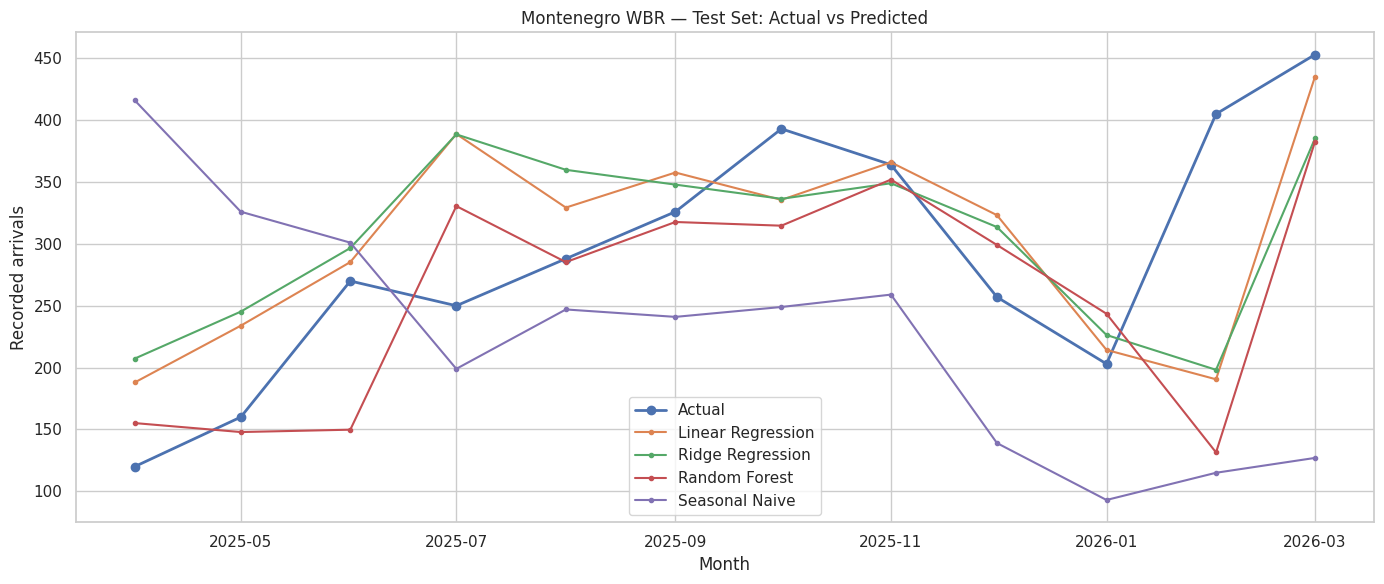

In [10]:
plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values, marker='o', linewidth=2, label='Actual')
for name, pred in predictions.items():
    plt.plot(y_test.index, pred, marker='.', label=name)
plt.title('Montenegro WBR — Test Set: Actual vs Predicted')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Time-series cross-validation

This uses expanding training windows within the training data. The final 12-month test set remains separate. Large variation between folds indicates unstable model performance.

In [16]:
n_splits = min(3, max(2, len(X_train) // 12))
tscv = TimeSeriesSplit(n_splits=n_splits)
cv_rows = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=tscv,
        scoring='neg_mean_absolute_error'
    )
    cv_rows.append({
        'Model': name,
        'Mean CV MAE': -scores.mean(),
        'Std CV MAE': scores.std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values('Mean CV MAE').round(2)
display(cv_results)

,Model,Mean CV MAE,Std CV MAE
2,Random Forest,183.53,53.64
0,Linear Regression,229.15,133.01
1,Ridge Regression,238.53,123.91


## 12. Select the model for the final forecast

Results on a separate test set and cross-validation results are presented. I avoided automatically selecting the "Random Forest" model. If the "seasonal-naive" (seasonal-naive) model, which serves as a starting point, although it shows better results. In the next cell, the model with the best MAE value among the three machine learning models is selected, disregarding the baseline.

In [12]:
BEST_MODEL_NAME = (
    results[results['Model'].isin(models.keys())]
    .sort_values('MAE')
    .iloc[0]['Model']
)

final_model = models[BEST_MODEL_NAME]
final_model.fit(X, y)
print('Selected model for Montenegro:', BEST_MODEL_NAME)

Selected model for Montenegro: Linear Regression


## 13. Recursive forecast for the next 3, 6 and 12 months — Montenegro only

The function forecasts one month at a time. Each predicted month is appended to the history and used to construct lag and rolling-average features for the next month. Forecast errors can accumulate, especially over 12 months.

In [13]:
def recursive_forecast_montenegro(history, fitted_model, feature_columns, horizon):
    values = list(history.astype(float).values)
    last_date = history.index[-1]
    future_dates = []
    forecast_values = []

    for step in range(1, horizon + 1):
        next_date = last_date + pd.DateOffset(months=step)
        next_features = pd.DataFrame([{
            'Time_Index': len(values),
            'Month_Sin': np.sin(2 * np.pi * next_date.month / 12),
            'Month_Cos': np.cos(2 * np.pi * next_date.month / 12),
            'Lag_1': values[-1],
            'Lag_3': values[-3],
            'Lag_6': values[-6],
            'Lag_12': values[-12],
            'Rolling_Mean_3': np.mean(values[-3:]),
            'Rolling_Mean_6': np.mean(values[-6:])
        }], columns=feature_columns)

        prediction = float(fitted_model.predict(next_features)[0])
        prediction = max(0.0, prediction)

        future_dates.append(next_date)
        forecast_values.append(prediction)
        values.append(prediction)

    return pd.Series(
        forecast_values,
        index=pd.DatetimeIndex(future_dates, name='Month'),
        name='Forecasted recorded arrivals'
    )

# Create one 12-month forecast. Its first 3 and 6 rows are the shorter horizons.
forecast_12 = recursive_forecast_montenegro(
    history=target,
    fitted_model=final_model,
    feature_columns=FEATURES,
    horizon=12
)

forecast_3 = forecast_12.iloc[:3].copy()
forecast_6 = forecast_12.iloc[:6].copy()

print('Forecast for the next 3 months:')
display(forecast_3.round(0).to_frame())

print('Forecast for the next 6 months:')
display(forecast_6.round(0).to_frame())

print('Forecast for the next 12 months:')
display(forecast_12.round(0).to_frame())

Forecast for the next 3 months:


,Forecasted recorded arrivals
Month,
2026-04-01,478.0
2026-05-01,553.0
2026-06-01,612.0


Forecast for the next 6 months:


,Forecasted recorded arrivals
Month,
2026-04-01,478.0
2026-05-01,553.0
2026-06-01,612.0
2026-07-01,628.0
2026-08-01,643.0
2026-09-01,631.0


Forecast for the next 12 months:


,Forecasted recorded arrivals
Month,
2026-04-01,478.0
2026-05-01,553.0
2026-06-01,612.0
2026-07-01,628.0
2026-08-01,643.0
2026-09-01,631.0
2026-10-01,573.0
2026-11-01,494.0
2026-12-01,418.0


## 14. Plot Montenegro historical data and 12-month forecast

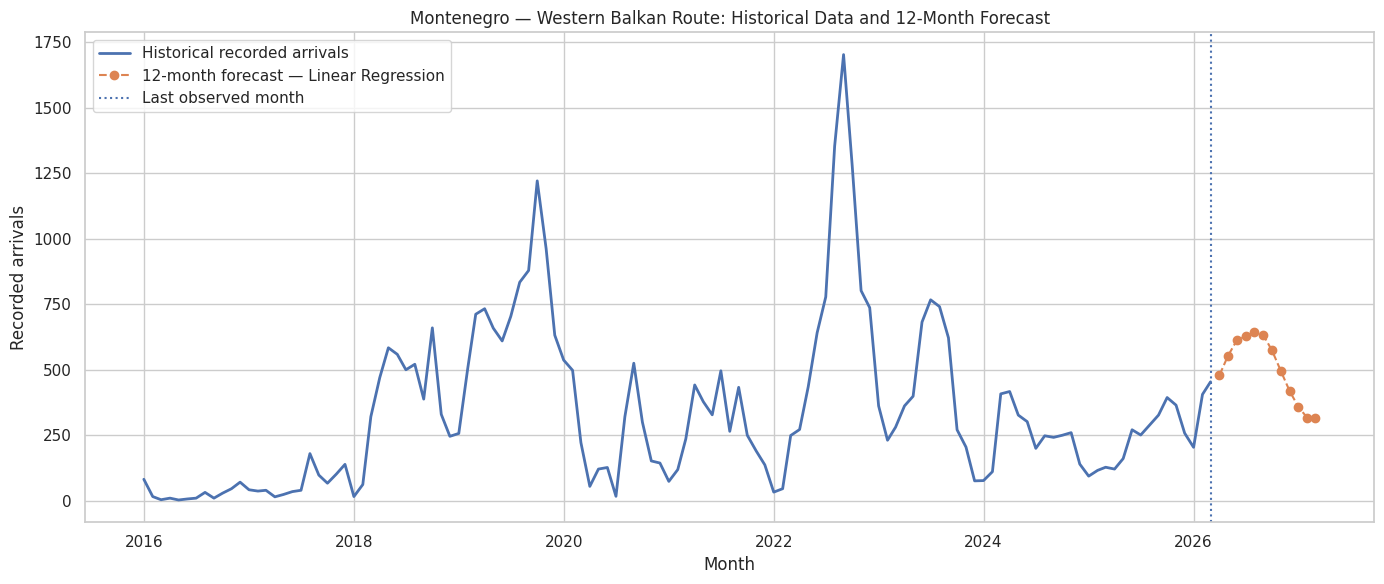

In [14]:
plt.figure(figsize=(14, 6))
plt.plot(target.index, target.values, label='Historical recorded arrivals', linewidth=2)
plt.plot(
    forecast_12.index, forecast_12.values,
    marker='o', linestyle='--',
    label=f'12-month forecast — {BEST_MODEL_NAME}'
)
plt.axvline(target.index[-1], linestyle=':', label='Last observed month')
plt.title('Montenegro — Western Balkan Route: Historical Data and 12-Month Forecast')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 15. Forecast summary and interpretation

The forecast uses historical arrivals and calendar patterns only. It does not include future policy decisions, border controls, conflicts, weather, or other external drivers. Recursive forecasts can accumulate errors over time.